In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\arwaa\Downloads\student_tea_snacks.csv")

# Display the first five rows
df.head()

,student_id,gender,age_group,prefers_tea,tea_type,snack_choice,cups_per_day
0,S001,Male,21-23,No,Black,Samosa,2
1,S002,Male,21-23,No,Green,Samosa,3
2,S003,Male,18-20,No,Doodh Patti,Biscuit,0
3,S004,Male,21-23,Yes,NaN,Samosa,1
4,S005,Male,18-20,Yes,Green,Samosa,4


In [3]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

Dataset shape: (100, 7)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   student_id    100 non-null    str  
 1   gender        100 non-null    str  
 2   age_group     100 non-null    str  
 3   prefers_tea   100 non-null    str  
 4   tea_type      77 non-null     str  
 5   snack_choice  100 non-null    str  
 6   cups_per_day  100 non-null    int64
dtypes: int64(1), str(6)
memory usage: 8.3 KB

Missing values in each column:
student_id       0
gender           0
age_group        0
prefers_tea      0
tea_type        23
snack_choice     0
cups_per_day     0
dtype: int64


In [4]:
tea_counts = df["tea_type"].value_counts()

print("Tea type preferences:")
print(tea_counts)

print("\nMost preferred tea type:", tea_counts.idxmax())
print("Number of students:", tea_counts.max())

Tea type preferences:
tea_type
Green          29
Doodh Patti    25
Black          23
Name: count, dtype: int64

Most preferred tea type: Green
Number of students: 29


In [5]:
average_cups_gender = df.groupby("gender")["cups_per_day"].mean()

print("Average cups per day by gender:")
print(average_cups_gender.round(2))

Average cups per day by gender:
gender
Female    2.6
Male      3.0
Name: cups_per_day, dtype: float64


Snack choices:
snack_choice
Samosa     40
Chips      31
Biscuit    29
Name: count, dtype: int64


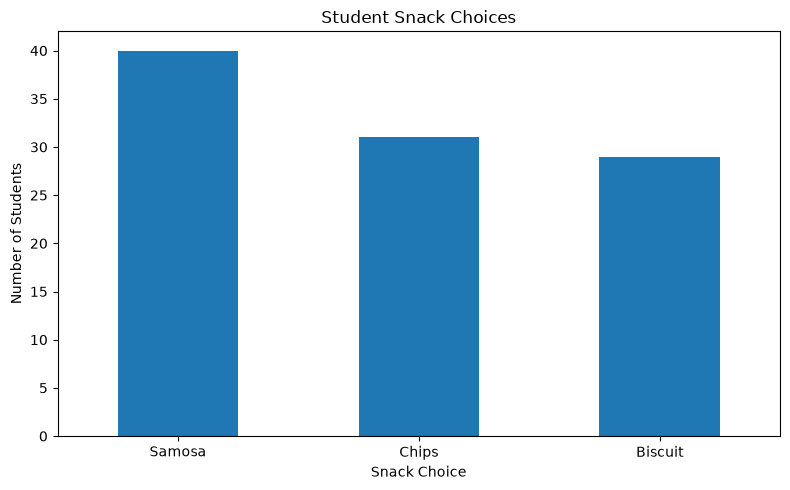

In [6]:
snack_counts = df["snack_choice"].value_counts()

print("Snack choices:")
print(snack_counts)

snack_counts.plot(kind="bar", figsize=(8, 5))
plt.title("Student Snack Choices")
plt.xlabel("Snack Choice")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
# Compare Yes/No tea preference by age group
age_preference = pd.crosstab(df["age_group"], df["prefers_tea"])

print("Tea preference (Yes/No) by age group:")
print(age_preference)

# Compare tea types by age group (missing tea types are excluded)
age_tea_type = pd.crosstab(df["age_group"], df["tea_type"])

print("\nTea types by age group:")
print(age_tea_type)

Tea preference (Yes/No) by age group:
prefers_tea  No  Yes
age_group           
18-20        19   20
21-23        17   15
24-26        13   16

Tea types by age group:
tea_type   Black  Doodh Patti  Green
age_group                           
18-20          9           11     13
21-23          9            6      5
24-26          5            8     11


Interpretation: The 18–20 age group has 20 students who prefer tea and 19 who do not. The 21–23 group has 15 who prefer tea and 17 who do not. The 24–26 group has 16 who prefer tea and 13 who do not. Among recorded tea types, Green is the most common choice in the 18–20 and 24–26 groups, while Black and Doodh Patti are tied in the 21–23 group.

In [8]:
non_tea_drinkers = (df["prefers_tea"].str.strip().str.lower() == "no").sum()

print("Number of students who don't drink tea:", non_tea_drinkers)

Number of students who don't drink tea: 49
